# Rural Wildfires in Portugal (SGIF 2001-2025)

## Objective

**Research question:** Do rural wildfire characteristics differ across different municipalities and differ between the periods before and after 2017?

1. Does the proportion of negligent versus intentional wildfires differ between the periods before and after 2017 in mainland Portugal?
2. Does the proportion of wildfires lasting more than 24 hours differ across the municipalities of Paredes, Castelo de Paiva, Évora, and Santarém?
3. Does the time to first intervention differ between the periods before and after 2017 in mainland Portugal?
4. Does the duration of rural wildfires differ across the municipalities of Paredes, Castelo de Paiva, Évora, and Santarém?
5. Is the time to first intervention associated with the burned area of rural wildfires in mainland Portugal?

## Variables per question

| Question | Response variable | Explanatory variable |
|---|---|---|
| 1 | `TipoCausa` (negligent / intentional) | period, from `Ano` |
| 2 | `IncSup24horas` (more than 24 h or not) | `Concelho` |
| 3 | time to first intervention = `DataHora_PrimeiraIntervencao` - `DataHoraAlerta` | period, from `Ano` |
| 4 | `Duracao_Horas` | `Concelho` |
| 5 | `AreaTotal_ha` | time to first intervention |

What each one is:

- `Codigo_SGIF`: id of the fire in the SGIF system
- `Ano`: year of the fire
- `Distrito`, `Concelho`: district and municipality
- `TipoCausa`: type of cause (Negligente, Intencional, Natural, Reacendimento, Desconhecida)
- `DataHoraAlerta`: date and time of the alert
- `DataHora_PrimeiraIntervencao`: date and time the first team started fighting the fire
- `DataHora_Extincao`: date and time the fire was put out
- `Duracao_Horas`: hours from alert to extinction
- `IncSup24horas`: 1 if the fire lasted more than 24 hours, 0 otherwise
- `AreaTotal_ha`: total burned area in hectares

`Distrito` and `DataHora_Extincao` are not in any question, we keep them to check `Concelho` and `Duracao_Horas`.

## Parameters

In [1]:
LAST_YEAR_BEFORE = 2017      # 2017 counts as "before". change to 2016 to move it to "after"
MUNICIPALITIES = ["Paredes", "Castelo de Paiva", "Évora", "Santarém"]

## Import data

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

data2001_2010 = pd.read_excel("Registos_Incendios_SGIF_2001_2010.xlsx")
data2011_2020 = pd.read_excel("Registos_Incendios_SGIF_2011_2020.xlsx")
data2021_2025 = pd.read_excel("Registos_Incendios_SGIF_2021_2025.xlsx")

# the three files have the same columns, so we stack them
data = pd.concat([data2001_2010, data2011_2020, data2021_2025], ignore_index=True)
data.shape

C:\Users\Kevin\AppData\Local\Temp\ipykernel_17472\2892379422.py:6: FutureWarning: Inferring datetime64[ns] from data containing strings is deprecated and will be removed in a future version. To retain the old behavior explicitly pass Series(data, dtype=datetime64[ns])
  data2001_2010 = pd.read_excel("Registos_Incendios_SGIF_2001_2010.xlsx")


(497478, 41)

## Keep only the variables we need

In [3]:
keep = ["Codigo_SGIF", "Ano", "Distrito", "Concelho", "TipoCausa",
        "DataHoraAlerta", "DataHora_PrimeiraIntervencao", "DataHora_Extincao",
        "Duracao_Horas", "IncSup24horas", "AreaTotal_ha"]
unused = [c for c in data.columns if c not in keep]

print("before:", data.shape)
print("dropped:", unused)
data = data.drop(columns=unused)
print("after: ", data.shape)
data.head()

before: (497478, 41)
dropped: ['Codigo_ANEPC', 'Mes', 'Dia', 'Hora', 'AreaPov_ha', 'AreaMato_ha', 'AreaAgric_ha', 'ClasseArea', 'DTCCFR', 'Freguesia', 'Local', 'RNAP', 'RNMPF', 'X_Militar', 'Y_Militar', 'Latitude', 'Longitude', 'X_ETRS89', 'Y_ETRS89', 'DSR', 'FWI', 'ISI', 'DC', 'DMC', 'FFMC', 'BUI', 'CodCausa', 'GrupoCausa', 'DescricaoCausa', 'FonteAlerta']
after:  (497478, 11)


,Codigo_SGIF,Ano,AreaTotal_ha,DataHoraAlerta,DataHora_PrimeiraIntervencao,DataHora_Extincao,Duracao_Horas,IncSup24horas,Distrito,Concelho,TipoCausa
0,AT901106,2001,0.0001,2001-01-05 02:00:00,NaT,2001-01-05 02:51:00,0.850000,0,Beja,Cuba,NaN
1,BL201479,2001,0.0100,2001-01-05 14:18:00,NaT,2001-01-05 14:23:00,0.083333,0,Coimbra,Coimbra,NaN
2,TM90152,2001,0.0100,2001-01-05 21:00:00,NaT,2001-01-05 22:35:00,1.583333,0,Bragança,Mirandela,NaN
3,BL101313,2001,0.1000,2001-01-06 13:05:00,NaT,2001-01-06 13:15:00,0.166667,0,Aveiro,Albergaria-a-Velha,NaN
4,BL201156,2001,0.0000,2001-01-07 00:16:00,NaT,2001-01-07 01:20:00,1.066667,0,Coimbra,Coimbra,NaN


## Data check

In [4]:
data.dtypes

Codigo_SGIF                             object
Ano                                      int64
AreaTotal_ha                           float64
DataHoraAlerta                  datetime64[ns]
DataHora_PrimeiraIntervencao    datetime64[ns]
DataHora_Extincao               datetime64[ns]
Duracao_Horas                          float64
IncSup24horas                            int64
Distrito                                object
Concelho                                object
TipoCausa                               object
dtype: object

In [5]:
# missing values per column
data.isna().sum()

Codigo_SGIF                          0
Ano                                  0
AreaTotal_ha                         0
DataHoraAlerta                       0
DataHora_PrimeiraIntervencao    214771
DataHora_Extincao                  513
Duracao_Horas                      513
IncSup24horas                        0
Distrito                             1
Concelho                             1
TipoCausa                       249994
dtype: int64

In [6]:
# missing values per year, only columns that have some
cols_na = data.columns[data.isna().any()]
data[cols_na].isna().groupby(data["Ano"]).sum()

,DataHora_PrimeiraIntervencao,DataHora_Extincao,Duracao_Horas,Distrito,Concelho,TipoCausa
Ano,,,,,,
2001,28915,0,0,0,0,26644
2002,28993,0,0,0,0,26327
2003,28087,0,0,0,0,25724
2004,27829,0,0,0,0,25691
2005,41689,0,0,0,0,38237
2006,24192,0,0,0,0,21169
2007,25131,0,0,0,0,15585
2008,2917,0,0,0,0,9185
2009,4045,1,1,0,0,15084


In [7]:
print("rows:", len(data))
print("unique Codigo_SGIF:", data["Codigo_SGIF"].nunique())
print("years:", data["Ano"].min(), "to", data["Ano"].max())

# Codigo_SGIF comes as text in some files and as number in others
data["Codigo_SGIF"].map(type).value_counts()

rows: 497478
unique Codigo_SGIF: 497478
years: 2001 to 2025


<class 'str'>    475448
<class 'int'>     22030
Name: Codigo_SGIF, dtype: int64

In [8]:
data[["Duracao_Horas", "IncSup24horas", "AreaTotal_ha"]].describe()

,Duracao_Horas,IncSup24horas,AreaTotal_ha
count,496965.000000,497478.000000,497478.000000
mean,1.947655,0.007210,6.994419
std,7.995199,0.084607,235.970910
min,0.000000,0.000000,0.000000
25%,0.566667,0.000000,0.010000
50%,1.033333,0.000000,0.050000
75%,1.800000,0.000000,0.500000
max,2474.316667,1.000000,65478.286936


In [9]:
print(data["TipoCausa"].value_counts(dropna=False))
print()
print(data["Distrito"].value_counts())

NaN              249994
Desconhecida      84395
Negligente        83660
Intencional       48013
Reacendimento     29376
Natural            2040
Name: TipoCausa, dtype: int64

Porto               105679
Braga                57121
Aveiro               40812
Lisboa               40704
Viseu                39210
Vila Real            32471
Viana do Castelo     29424
Santarém             22334
Setúbal              19149
Guarda               17764
Leiria               17492
Bragança             16176
Coimbra              15063
Castelo Branco       12887
Faro                  9385
Beja                  7195
Portalegre            6310
Évora                 6236
Viana Do Castelo      2064
BRAGA                    1
Name: Distrito, dtype: int64


In [10]:
# our municipalities, ignoring upper/lower case
ours = [m.lower() for m in MUNICIPALITIES]
mask = data["Concelho"].str.lower().isin(ours)
data.loc[mask].groupby(["Distrito", "Concelho"]).size()

Distrito  Concelho        
Aveiro    Castelo De Paiva       41
          Castelo de Paiva     1359
Porto     Paredes             12512
Santarém  Santarém             2987
Évora     Évora                1632
dtype: int64

What we see:

- No duplicated fires: one row per `Codigo_SGIF`. But the id comes as text in some files and as a number in others, so it has to be one type.
- All 18 districts are in mainland Portugal, so there is nothing to remove for "mainland". `Distrito` has case problems (`Viana Do Castelo`, `BRAGA`).
- `Castelo de Paiva` also shows up as `Castelo De Paiva` (41 fires). The four municipalities fall in the expected districts.
- `TipoCausa` is missing for 250k fires, mostly before 2014. This matters for question 1.
- `DataHora_PrimeiraIntervencao` is missing in almost all fires from 2001 to 2007, so question 3 and 5 have little data there.
- `Duracao_Horas` and `DataHora_Extincao` are missing in the same 513 rows. Duration goes from 0 to 2474 hours.
- One fire in 2024 has no `Distrito` or `Concelho`.

## Cleaning: municipalities and types

We work at the municipality level (`Concelho`). Paredes and Castelo de Paiva are only municipalities. Évora and Santarém are also district names, but we want the municipality, not the whole district (for example Évora has 6236 fires as a district and 1632 as a municipality).

`Distrito` was only kept to check that, so we drop it now.

In [11]:
# the fire with no municipality can't be used
print("no Concelho:", data["Concelho"].isna().sum())
data = data.dropna(subset=["Concelho"])

data = data.drop(columns=["Distrito"])
data.shape

no Concelho: 1


(497477, 10)

In [12]:
# same municipality written with different case: "Castelo de Paiva" / "Castelo De Paiva", "ODIVELAS" / "Odivelas"
print("names before:", data["Concelho"].nunique())
data["Concelho"] = data["Concelho"].str.title()
print("names after: ", data["Concelho"].nunique())

MUNICIPALITIES = [m.title() for m in MUNICIPALITIES]
data.loc[data["Concelho"].isin(MUNICIPALITIES), "Concelho"].value_counts()

names before: 379


names after:  278


Paredes             12512
Santarém             2987
Évora                1632
Castelo De Paiva     1400
Name: Concelho, dtype: int64

From 379 names to 278, which is the number of municipalities in mainland Portugal. Castelo de Paiva goes from 1359 to 1400 fires.

In [13]:
# the id is an id, not a number
data["Codigo_SGIF"] = data["Codigo_SGIF"].astype("string")

# text with few values -> category
data["Concelho"] = data["Concelho"].astype("category")
data["TipoCausa"] = data["TipoCausa"].astype("category")

data.dtypes

Codigo_SGIF                             string
Ano                                      int64
AreaTotal_ha                           float64
DataHoraAlerta                  datetime64[ns]
DataHora_PrimeiraIntervencao    datetime64[ns]
DataHora_Extincao               datetime64[ns]
Duracao_Horas                          float64
IncSup24horas                            int64
Concelho                              category
TipoCausa                             category
dtype: object

## Period

In [14]:
# before = up to LAST_YEAR_BEFORE, after = the rest
data["period"] = "after"
data.loc[data["Ano"] <= LAST_YEAR_BEFORE, "period"] = "before"
data["period"] = data["period"].astype("category")

data.groupby("period")["Ano"].agg(["min", "max", "count"])

,min,max,count
period,,,
after,2018,2025,73330
before,2001,2017,424147


## Question 1: cause

In [15]:
# astype(str) so the missing causes show up as "nan"
pd.crosstab(data["TipoCausa"].astype(str), data["period"], margins=True)

period,after,before,All
TipoCausa,,,
Desconhecida,23829,60566,84395
Intencional,13872,34141,48013
Natural,836,1204,2040
Negligente,26201,57459,83660
Reacendimento,3820,25556,29376
nan,4772,245221,249993
All,73330,424147,497477


In [16]:
# only fires with a known negligent or intentional cause
q1 = data[data["TipoCausa"].isin(["Negligente", "Intencional"])]

tab = pd.crosstab(q1["period"], q1["TipoCausa"].astype(str), margins=True)
tab["share negligent"] = (tab["Negligente"] / tab["All"]).round(3)
tab

TipoCausa,Intencional,Negligente,All,share negligent
period,,,,
after,13872,26201,40073,0.654
before,34141,57459,91600,0.627
All,48013,83660,131673,0.635


In [17]:
# how many causes were classified each year
by_year = pd.crosstab(q1["Ano"], q1["TipoCausa"].astype(str))
by_year["share negligent"] = (by_year["Negligente"] / by_year.sum(axis=1)).round(2)
by_year

TipoCausa,Intencional,Negligente,share negligent
Ano,,,
2001,475,391,0.45
2002,394,414,0.51
2003,436,522,0.54
2004,364,421,0.54
2005,619,456,0.42
2006,381,502,0.57
2007,1424,3203,0.69
2008,1570,3490,0.69
2009,3540,5190,0.59


For question 1 we keep only the fires with cause `Negligente` or `Intencional`. Missing, unknown, rekindling and natural causes are left out, we don't impute a cause.

## Questions 2 and 4: duration

In [18]:
print("missing duration:", data["Duracao_Horas"].isna().sum())
print("duration = 0:    ", (data["Duracao_Horas"] == 0).sum())

# a fire can't be put out the same minute it is reported, and without duration we can't use it
before = len(data)
data = data[data["Duracao_Horas"] > 0]
print("rows removed:", before - len(data), "of", before)

missing duration: 513
duration = 0:     636
rows removed: 1149 of 497477


In [19]:
# IncSup24horas should be 1 when the fire lasted 24 hours or more
print("mismatches with > 24: ", ((data["Duracao_Horas"] > 24).astype(int) != data["IncSup24horas"]).sum())
print("mismatches with >= 24:", ((data["Duracao_Horas"] >= 24).astype(int) != data["IncSup24horas"]).sum())

mismatches with > 24:  29
mismatches with >= 24: 0


The 29 mismatches are fires of exactly 24 hours. SGIF counts them as "more than 24 hours", so `IncSup24horas` is fine as it is.

In [20]:
q24 = data[data["Concelho"].isin(MUNICIPALITIES)].copy()
q24["Concelho"] = q24["Concelho"].cat.remove_unused_categories()

pd.crosstab(q24["Concelho"], q24["IncSup24horas"], margins=True)

IncSup24horas,0,1,All
Concelho,,,
Castelo De Paiva,1384,8,1392
Paredes,12456,36,12492
Santarém,2959,26,2985
Évora,1622,9,1631
All,18421,79,18500


In [21]:
q24.groupby("Concelho")["Duracao_Horas"].describe()

,count,mean,std,min,25%,50%,75%,max
Concelho,,,,,,,,
Castelo De Paiva,1392.0,1.790577,4.209986,0.050000,0.566667,1.083333,1.666667,83.250000
Paredes,12492.0,1.278609,2.831771,0.016667,0.500000,0.816667,1.250000,143.600000
Santarém,2985.0,1.552446,4.063688,0.016667,0.383333,0.816667,1.450000,82.666667
Évora,1631.0,1.280421,2.416428,0.066667,0.416667,0.700000,1.250000,29.050000


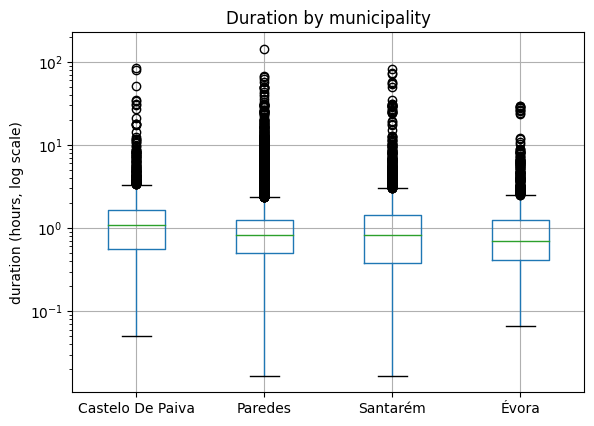

In [22]:
fig, ax = plt.subplots()
q24.boxplot(column="Duracao_Horas", by="Concelho", ax=ax)
ax.set_yscale("log")
ax.set_xlabel("")
ax.set_ylabel("duration (hours, log scale)")
ax.set_title("Duration by municipality")
plt.suptitle("")
plt.show()

We keep the long fires (up to 144 hours in Paredes). They are outliers, but real ones: big fires that tell us about specific events. Duration is very skewed (median around 1 hour), so the log scale is needed to see anything.

## Questions 3 and 5: time to first intervention

There is no column with this time, we compute it from the alert and the first intervention.

In [23]:
data["time_first_intervention_min"] = (data["DataHora_PrimeiraIntervencao"] - data["DataHoraAlerta"]).dt.total_seconds() / 60
data["time_first_intervention_min"].describe()

count    2.821910e+05
mean     3.846804e+01
std      1.287085e+04
min      0.000000e+00
25%      7.000000e+00
50%      1.100000e+01
75%      1.600000e+01
max      6.837131e+06
Name: time_first_intervention_min, dtype: float64

In [24]:
# the first intervention date only exists from 2008
data.groupby("Ano")["time_first_intervention_min"].count()

Ano
2001        0
2002        0
2003        0
2004        0
2005        0
2006       51
2007        1
2008    16040
2009    25737
2010    23765
2011    29526
2012    25211
2013    23051
2014     9355
2015    19632
2016    16090
2017    20983
2018    12268
2019    10696
2020     9565
2021     8160
2022    10350
2023     7511
2024     6111
2025     8088
Name: time_first_intervention_min, dtype: int64

Before 2008 there is almost no intervention date (51 fires in 2006, 1 in 2007), so for question 3 the "before" period is really 2008 to 2017.

In [25]:
# intervention after extinction is not possible, and time = 0 looks like the alert time copied
after_ext = data["DataHora_PrimeiraIntervencao"] > data["DataHora_Extincao"]
zero = data["time_first_intervention_min"] == 0
print("intervention after extinction:", after_ext.sum())
print("time = 0:                     ", zero.sum())

# only the time is wrong, the fire is still fine for the other questions
data.loc[after_ext | zero, "time_first_intervention_min"] = None
data["time_first_intervention_min"].describe()

intervention after extinction: 3968
time = 0:                      2387


count    275836.000000
mean         13.943822
std          25.574472
min           1.000000
25%           7.000000
50%          11.000000
75%          16.000000
max        1488.000000
Name: time_first_intervention_min, dtype: float64

In [26]:
data.groupby("period")["time_first_intervention_min"].agg(["count", "median", "mean"])

,count,median,mean
period,,,
after,71456,13.0,16.104764
before,204380,10.0,13.188306


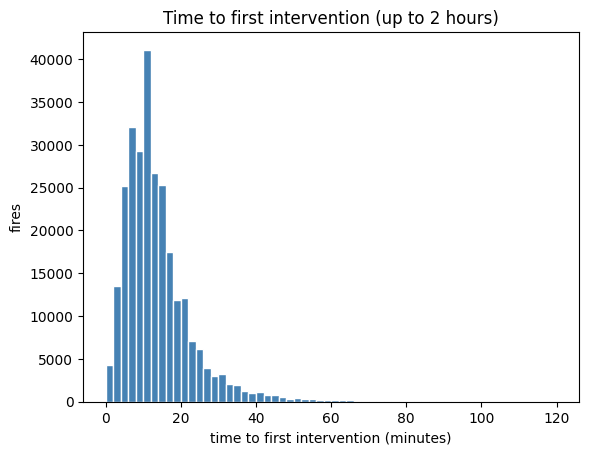

In [27]:
fig, ax = plt.subplots()
ax.hist(data["time_first_intervention_min"].dropna(), bins=range(0, 121, 2), color="steelblue", edgecolor="white")
ax.set_xlabel("time to first intervention (minutes)")
ax.set_ylabel("fires")
ax.set_title("Time to first intervention (up to 2 hours)")
plt.show()